# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [9]:
# Your data checks here
print("--------------------------------------------------------------------------------")
print(df.shape)
print("--------------------------------------------------------------------------------")
print(df.dtypes)
print("--------------------------------------------------------------------------------")
print(df.isna().sum())
print("--------------------------------------------------------------------------------")
print(df.duplicated().sum())
print("--------------------------------------------------------------------------------")
df.describe()

--------------------------------------------------------------------------------
(100000, 13)
--------------------------------------------------------------------------------
user_id          int64
movie_id         int64
rating           int64
timestamp       object
age              int64
gender          object
occupation      object
zip_code        object
title           object
year           float64
decade         float64
genres          object
rating_year      int64
dtype: object
--------------------------------------------------------------------------------
user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64
--------------------------------------------------------------------------------
0
--------------------------------------------------------------------------------


,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00000,100000.000000,100000.000000,100000.000000,99970.000000,99970.000000,100000.000000
mean,462.48475,425.530130,3.529860,32.969850,1987.748224,1982.780134,1997.471010
std,266.61442,330.798356,1.125674,11.562623,14.140014,13.820687,0.499161
min,1.00000,1.000000,1.000000,7.000000,1922.000000,1920.000000,1997.000000
25%,254.00000,175.000000,3.000000,24.000000,1986.000000,1980.000000,1997.000000
50%,447.00000,322.000000,4.000000,30.000000,1994.000000,1990.000000,1997.000000
75%,682.00000,631.000000,4.000000,40.000000,1996.000000,1990.000000,1998.000000
max,943.00000,1682.000000,5.000000,73.000000,1998.000000,1990.000000,1998.000000


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_
100k ratings, no duplicates. 30 rows missing year/decade (kept). Ratings skew high (mean 3.5). All rated 1997–98 movies mostly post-1986.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count Movies
- Why: Counting ratings would measure popularity instead

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Mean of all individual ratings for movies in that genre and drop genres with fewer than 500 ratings and the unkown genre
- Why: Each rating is one persons and averages from tiny samples are unreliable and would skew the ranking

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Average rating by the movie's release year and group by decade or only keep years with at least 100 ratings and dorp the 30 without any release year
- Why: Older years have fewer ratings and would be too noisy

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movies rating is the mean of its individual ratings. >= 50 and I would break ties by # of ratings (more first) then by titles
- Why: The question says “at least,” which means ≥. More ratings means a more reliable average so that’s a fair tiebreaker.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

Movies: 1682
Avg genres per movie: 1.72
             movies  % of movies
genre                           
Drama           725         43.1
Comedy          505         30.0
Thriller        251         14.9
Action          251         14.9
Romance         247         14.7
Adventure       135          8.0
Children        122          7.3
Crime           109          6.5
Sci-Fi          101          6.0
Horror           92          5.5
War              71          4.2
Mystery          61          3.6
Musical          56          3.3
Documentary      50          3.0
Animation        42          2.5
Western          27          1.6
Film-Noir        24          1.4
Fantasy          22          1.3
unknown           2          0.1


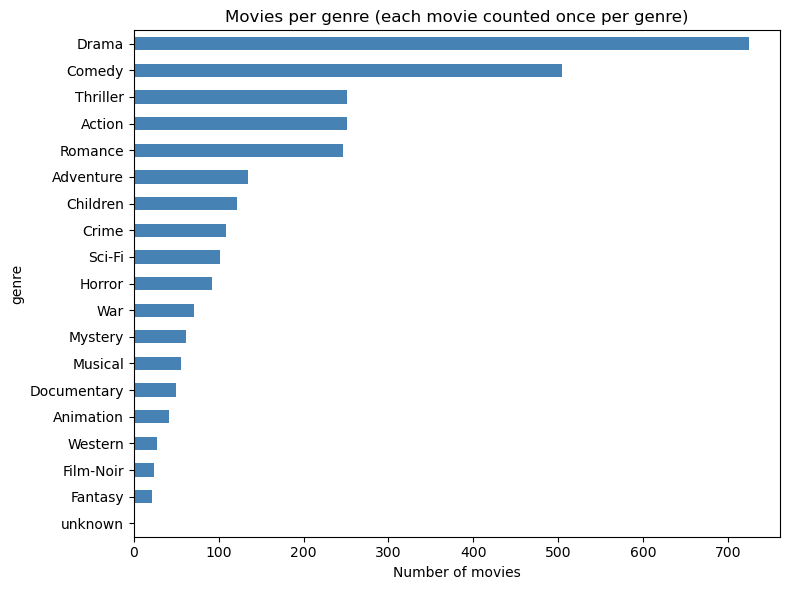

In [13]:
movies = df.drop_duplicates("movie_id")[["movie_id", "title", "genres"]]
movie_genres = movies.assign(genre=movies["genres"].str.split("|")).explode("genre")

genre_counts = movie_genres["genre"].value_counts()
summary = pd.DataFrame({
    "movies": genre_counts,
    "% of movies": (genre_counts / len(movies) * 100).round(1),
})
print("Movies:", len(movies))
print("Avg genres per movie:", round(len(movie_genres) / len(movies), 2))

print(summary)

fig, ax = plt.subplots(figsize=(8, 6))
genre_counts.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Number of movies")
ax.set_title("Movies per genre (each movie counted once per genre)")
plt.tight_layout()
plt.show()

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

I counted movies not ratings: each of the 1,682 movies counts once in every genre it has (avg 1.72 genres per movie), so percentages add up to more than 100%.

Drama  with 725 movies (43.1%), followed by Comedy at 505 (30.0%). The next tier Thriller and Action (251 each, 14.9%) and Romance (247, 14.7%) is about a third the size of Drama. The smallest genres, Western (27), Film-Noir (24), and Fantasy (22), each make up under 2% of movies. Two movies have an unknown genre.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

In [ ]:
# Q2: your code here


**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

In [ ]:
# Q3: your code here


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [ ]:
# Q4: your code here


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

**Prompt 2**
- What I asked:
- AI's first attempt:
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q2**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q3**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**Q4**
- Dashboard says:
- I say:
- Same? (yes / partly / no):
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q2**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q3**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q4**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week